# Pj1 RET503 - Sistem Persepsi Robot Quadruped 12 DOF (Inspeksi Kualitas Udara dan Termal Indoor)
Kelas dideteksi: **person, laptop, tv, chair** (subset COCO val2017).


## 0. Persiapan

In [ ]:
!nvidia-smi -L
!pip install -q ultralytics opencv-python

GPU 0: Tesla T4 (UUID: GPU-69d77799-3cfd-a3d2-f5de-cd7740ac81c0)
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 3.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 43.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.2/97.2 kB 10.3 MB/s eta 0:00:00


In [21]:
NIM  = "4222411045"
NAMA = "Cyntia Elisabeth Lumbantoruan"
KELAS = "person laptop tv chair"
JUMLAH = 600

In [ ]:
from google.colab import files
up = files.upload()
import glob, os
for z in glob.glob("*.zip"):
    !unzip -o -j "{z}" "*.py" -d .
!ls *.py

Saving 00_ambil_subset_coco.py to 00_ambil_subset_coco.py
Saving 01_cek_anotasi.py to 01_cek_anotasi.py
Saving 02_yolo_ke_coco.py to 02_yolo_ke_coco.py
Saving 03_coco_ke_yolo.py to 03_coco_ke_yolo.py
Saving 05_split_dataset_yolo.py to 05_split_dataset_yolo.py
Saving 06_latih_bandingkan.py to 06_latih_bandingkan.py
00_ambil_subset_coco.py  02_yolo_ke_coco.py  05_split_dataset_yolo.py
01_cek_anotasi.py	 03_coco_ke_yolo.py  06_latih_bandingkan.py


## Tahap 1 - Siapkan dataset dan cek anotasi

In [ ]:
!python 00_ambil_subset_coco.py --kelas {KELAS} --jumlah 600

Kelas dipilih: ['person', 'laptop', 'tv', 'chair'] | jumlah gambar: 600
(Ubah dengan: python 00_ambil_subset_coco.py --kelas <nama1> <nama2> --jumlah <n>)

Kelas baru      : 0 = person, 1 = laptop, 2 = tv, 3 = chair
Gambar berobjek : 600
Gambar latar    : 60
Jumlah kotak    : person 2158, laptop 58, tv 55, chair 447
Siap di dataset_yolo/ -> lanjutkan dengan: python 01_cek_anotasi.py dataset_yolo


In [ ]:
!python 01_cek_anotasi.py dataset_yolo

Gambar          : 660
Tanpa file label: 0
Label kosong    : 60 (gambar latar tanpa objek)
Jumlah kotak per kelas:
  person    : 2158
  laptop    : 58
  tv        : 55
  chair     : 447

180 masalah ditemukan:
  [!] 000000005586.txt baris 6: kotak sangat kecil (8x13 px)
  [!] 000000005586.txt baris 12: kotak sangat kecil (10x6 px)
  [!] 000000007977.txt baris 2: kotak sangat kecil (8x14 px)
  [!] 000000007977.txt baris 3: kotak sangat kecil (7x14 px)
  [!] 000000007977.txt baris 4: kotak sangat kecil (4x10 px)
  [!] 000000007977.txt baris 5: kotak sangat kecil (7x17 px)
  [!] 000000013348.txt baris 1: kotak sangat kecil (6x21 px)
  [!] 000000013348.txt baris 4: kotak sangat kecil (7x11 px)
  [!] 000000013348.txt baris 5: kotak sangat kecil (4x6 px)
  [!] 000000017959.txt baris 4: kotak sangat kecil (6x15 px)
  [!] 000000017959.txt baris 5: kotak sangat kecil (7x13 px)
  [!] 000000017959.txt baris 6: kotak sangat kecil (6x8 px)
  [!] 000000017959.txt baris 7: kotak sangat kecil (6x17 px)

Lihat beberapa gambar hasil cek visual

In [ ]:
import glob, cv2
salah = 0
for f in glob.glob("dataset_yolo/labels/*.txt"):
    for b in open(f).read().splitlines():
        v = b.split()
        if not b.strip(): continue
        if len(v) != 5 or not all(0 <= float(t) <= 1 for t in v[1:]) or not 0 <= int(v[0]) <= 3:
            salah += 1; print(f, b)
print("Baris berformat salah:", salah)

Baris berformat salah: 0


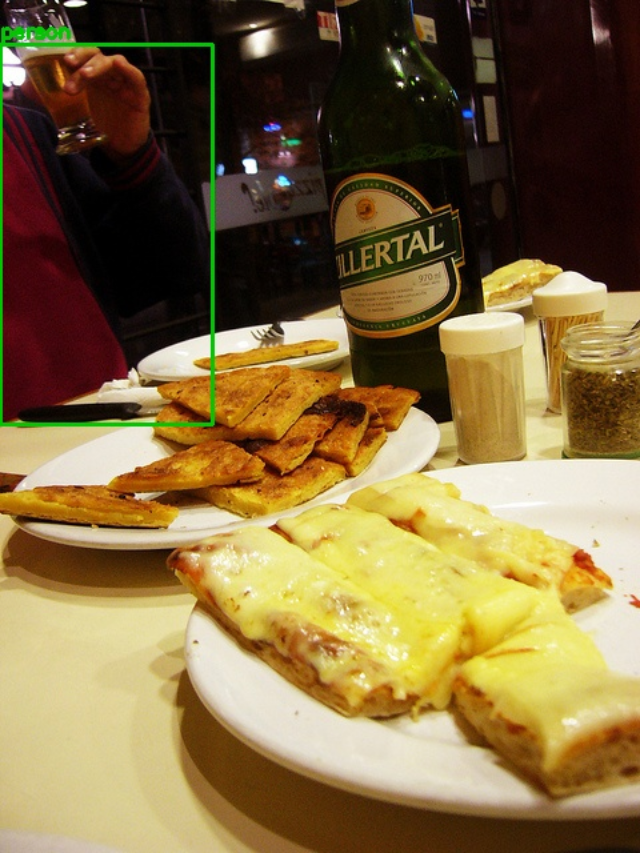

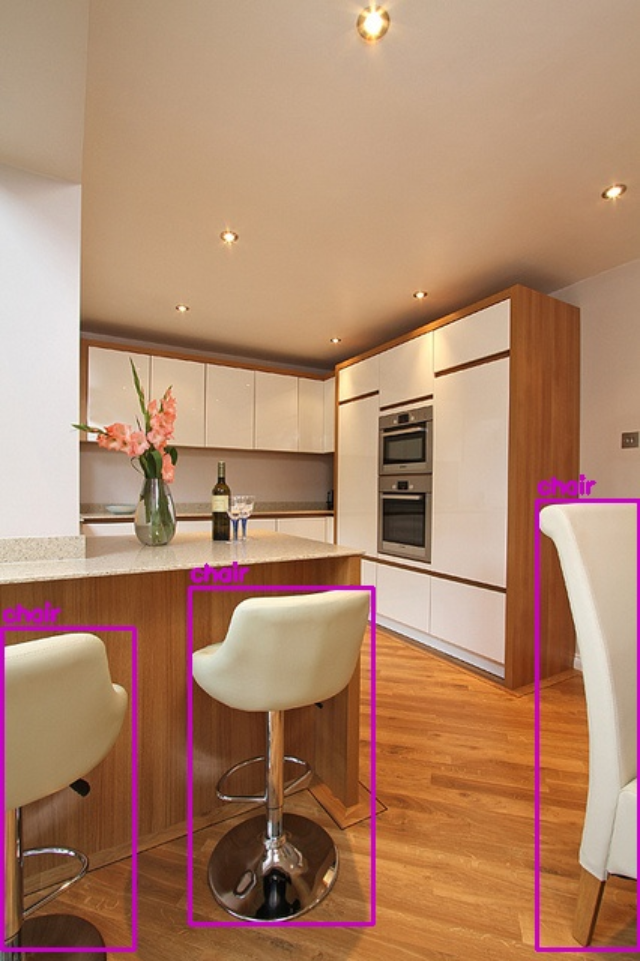

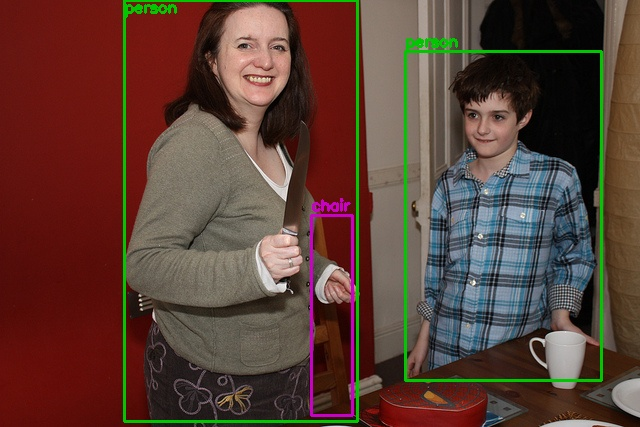

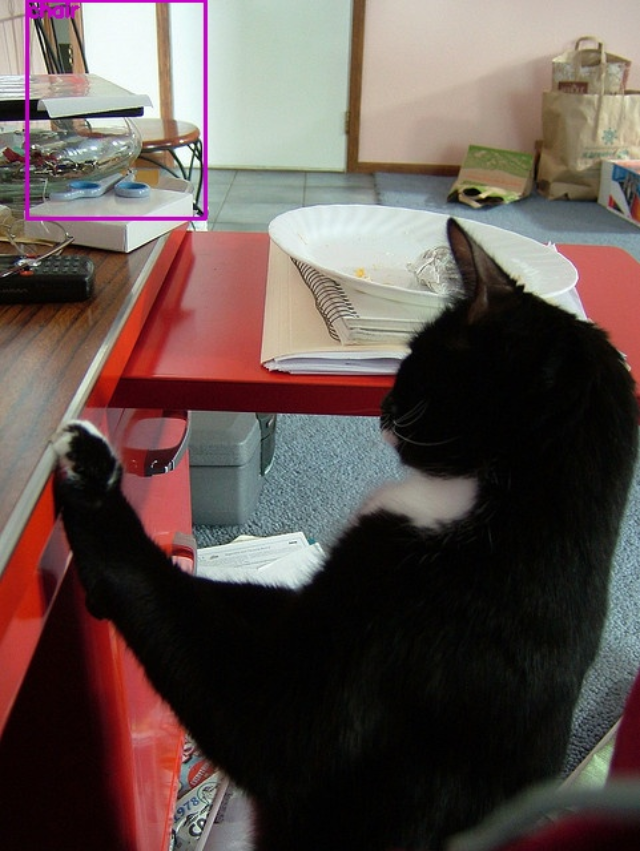

In [ ]:
import glob, cv2, random
from google.colab.patches import cv2_imshow
fs = sorted(glob.glob("dataset_yolo/cek_visual/*.jpg"))
random.seed(1)
for f in random.sample(fs, 4):
    im = cv2.imread(f); h, w = im.shape[:2]
    cv2_imshow(cv2.resize(im, (640, int(640*h/w))))

## Tahap 2 - Konversi format dan pembagian data

In [ ]:
!python 02_yolo_ke_coco.py dataset_yolo
!python 03_coco_ke_yolo.py dataset_yolo/annotations_coco.json hasil_yolo
!python 05_split_dataset_yolo.py dataset_yolo dataset_v1

660 gambar, 2718 kotak, 4 kategori -> dataset_yolo/annotations_coco.json
660 file label dibuat di hasil_yolo/labels
train: 461 gambar
val  : 132 gambar
test : 67 gambar

data.yaml dibuat di dataset_v1/data.yaml


In [ ]:
import glob, os
beda = 0
for f in glob.glob("dataset_yolo/labels/*.txt"):
    a = [list(map(float, l.split())) for l in open(f).read().splitlines() if l.strip()]
    g = "hasil_yolo/labels/" + os.path.basename(f)
    b = [list(map(float, l.split())) for l in open(g).read().splitlines() if l.strip()]
    if len(a) != len(b) or any(abs(x - y) > 1e-4 for r, s in zip(a, b) for x, y in zip(r, s)):
        beda += 1
print("File label yang berbeda:", beda)

File label yang berbeda: 0


## Tahap 3-5 - Latih E1, E2, E3, pilih model terbaik, uji di test

In [ ]:
MODEL = "yolo26n"
!python 06_latih_bandingkan.py --nim {NIM} --nama "{NAMA}" --model {MODEL} --epochs 30

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.

=== E1_pretrained: yolo26n.pt | pretrained=True | pengaturan dasar ===
Ultralytics 8.4.178 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=dataset_v1/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=Tr

## Hasil

In [ ]:
print(open(f"hasil_praktik_{NIM}.txt", encoding="utf-8").read())

  PRAKTIK TERPADU MINGGU 4-7 - RET503
  NIM / Nama    : 4222411045 / Cyntia Elisabeth Lumbantoruan
  Waktu         : 16-10-2026 19:35:49
  Komputer/user : 53c3187b78e6 / root
  Dataset       : dataset_v1  (sidik jari label: 5F296EAA5CF8)
  Pengaturan    : model yolo26n, epochs 30, imgsz 416, batch 16
  Eksperimen     Perubahan        mAP50  mAP50-95      P      R     ms   menit
  E1_pretrained  -                0.573     0.366  0.591  0.525    5.1     3.8
  E2_scratch     -                0.040     0.013  0.819  0.043    2.9     3.4
  E3_tuning      imgsz=640        0.635     0.412  0.728  0.525    6.3     4.5
  Model terpilih (mAP50-95 val tertinggi): E3_tuning
  Hasil di data TEST (sekali saja)       : mAP50 0.640 | mAP50-95 0.465



In [ ]:
import pandas as pd
pd.read_csv(f"hasil_praktik_{NIM}.csv").drop(columns=["bobot"])

,eksperimen,perubahan,pretrained,mAP50,mAP50-95,precision,recall,inferensi_ms,waktu_latih_menit,imgsz
0,E1_pretrained,-,True,0.5725,0.3661,0.5906,0.5246,5.13,3.82,416
1,E2_scratch,-,False,0.0401,0.0135,0.8192,0.0435,2.93,3.44,416
2,E3_tuning,imgsz=640,True,0.6354,0.4119,0.7281,0.5253,6.29,4.53,640


E1_pretrained


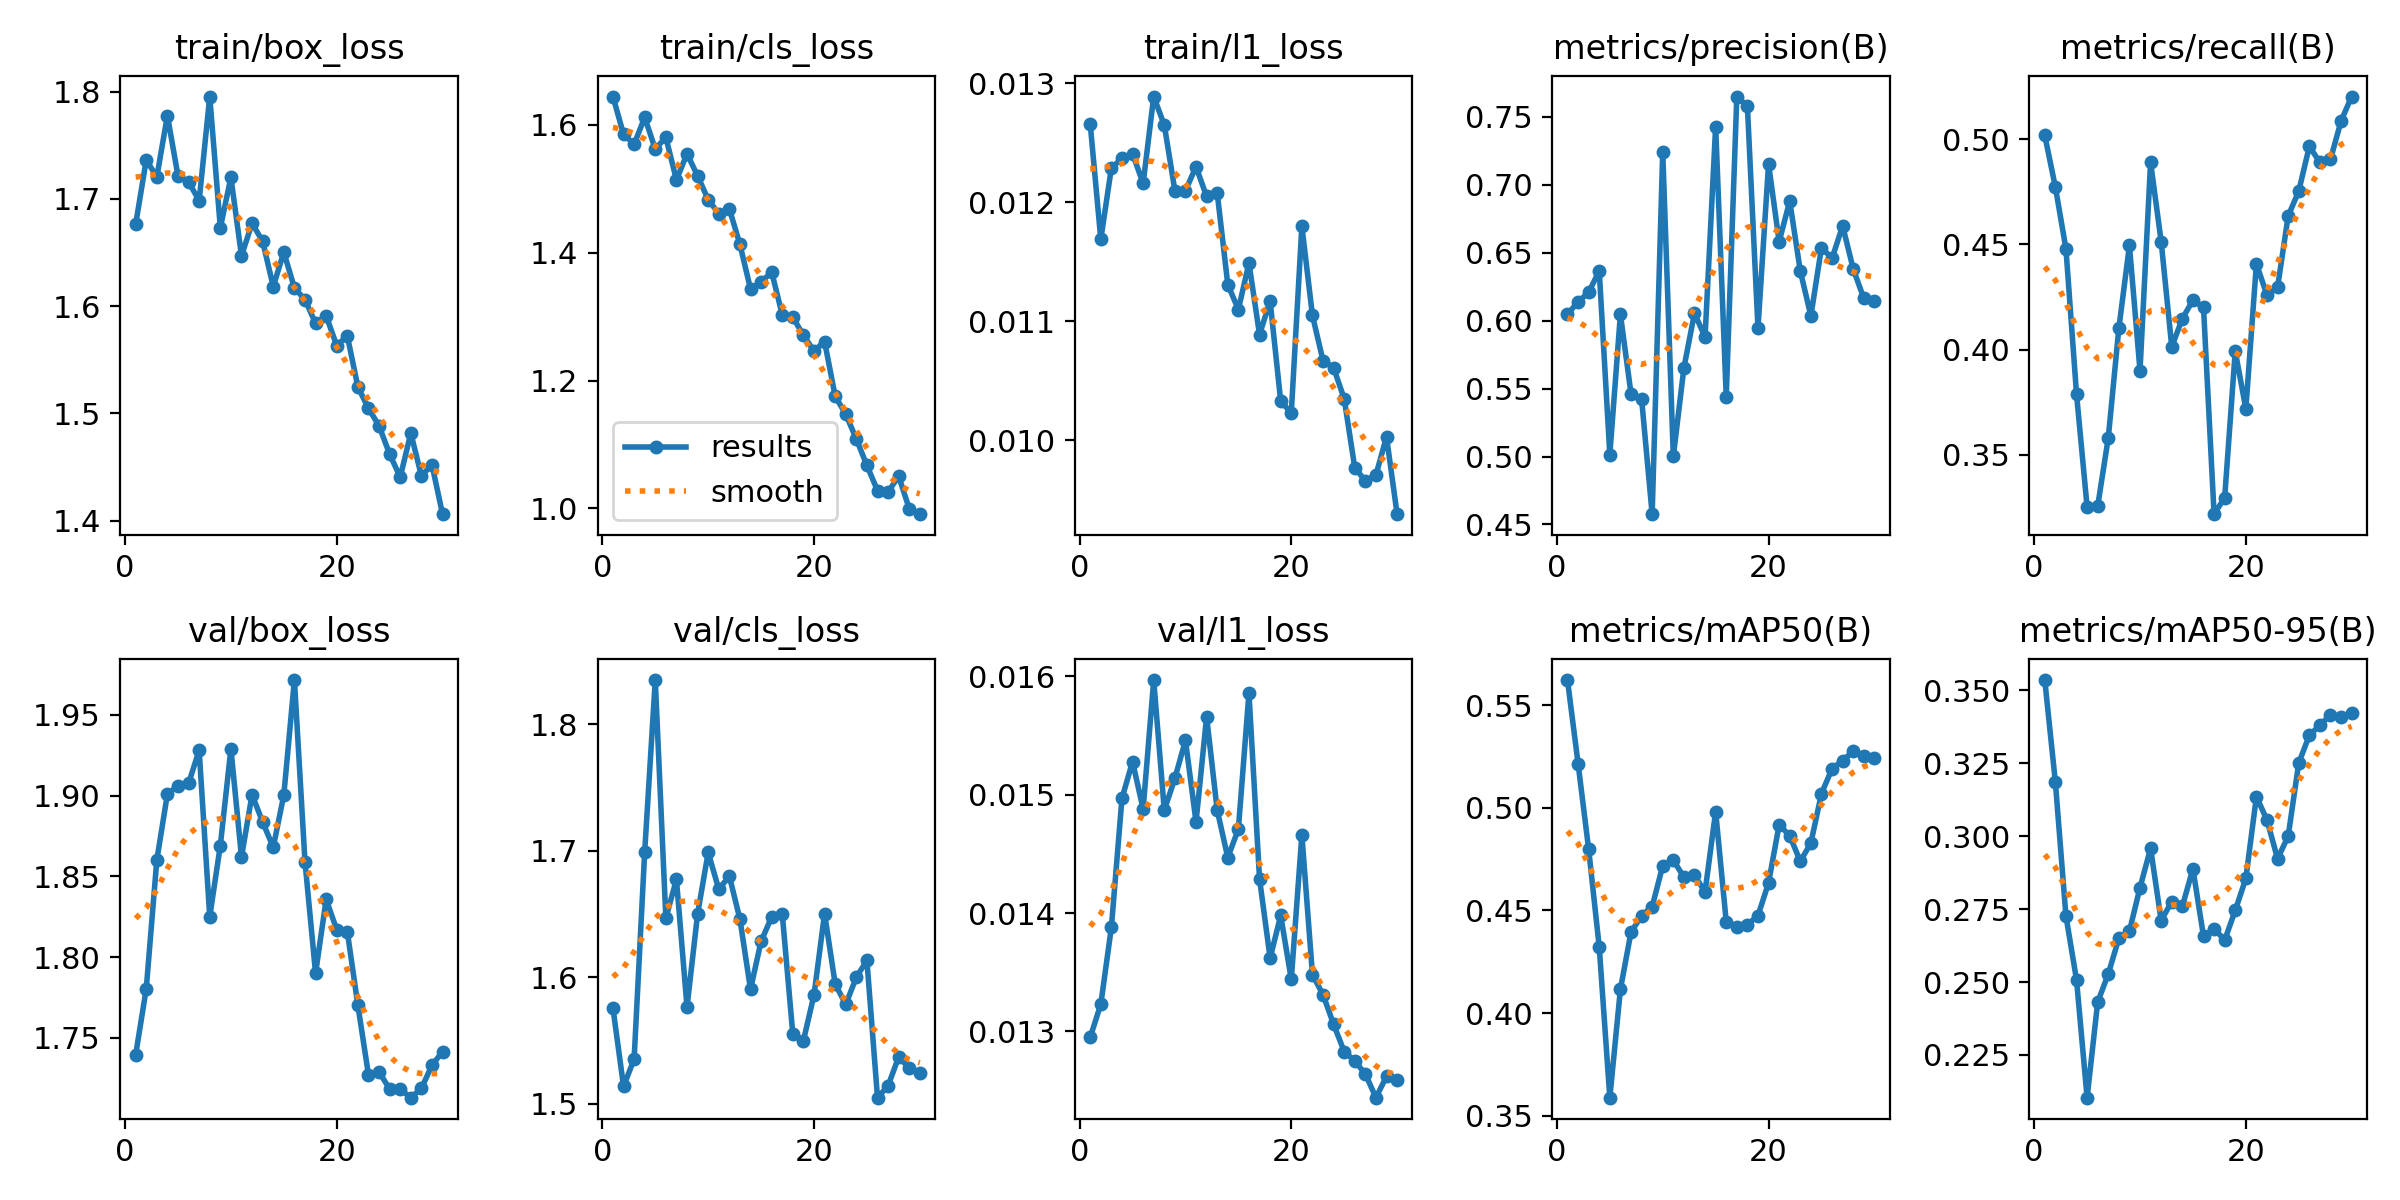

E3_tuning


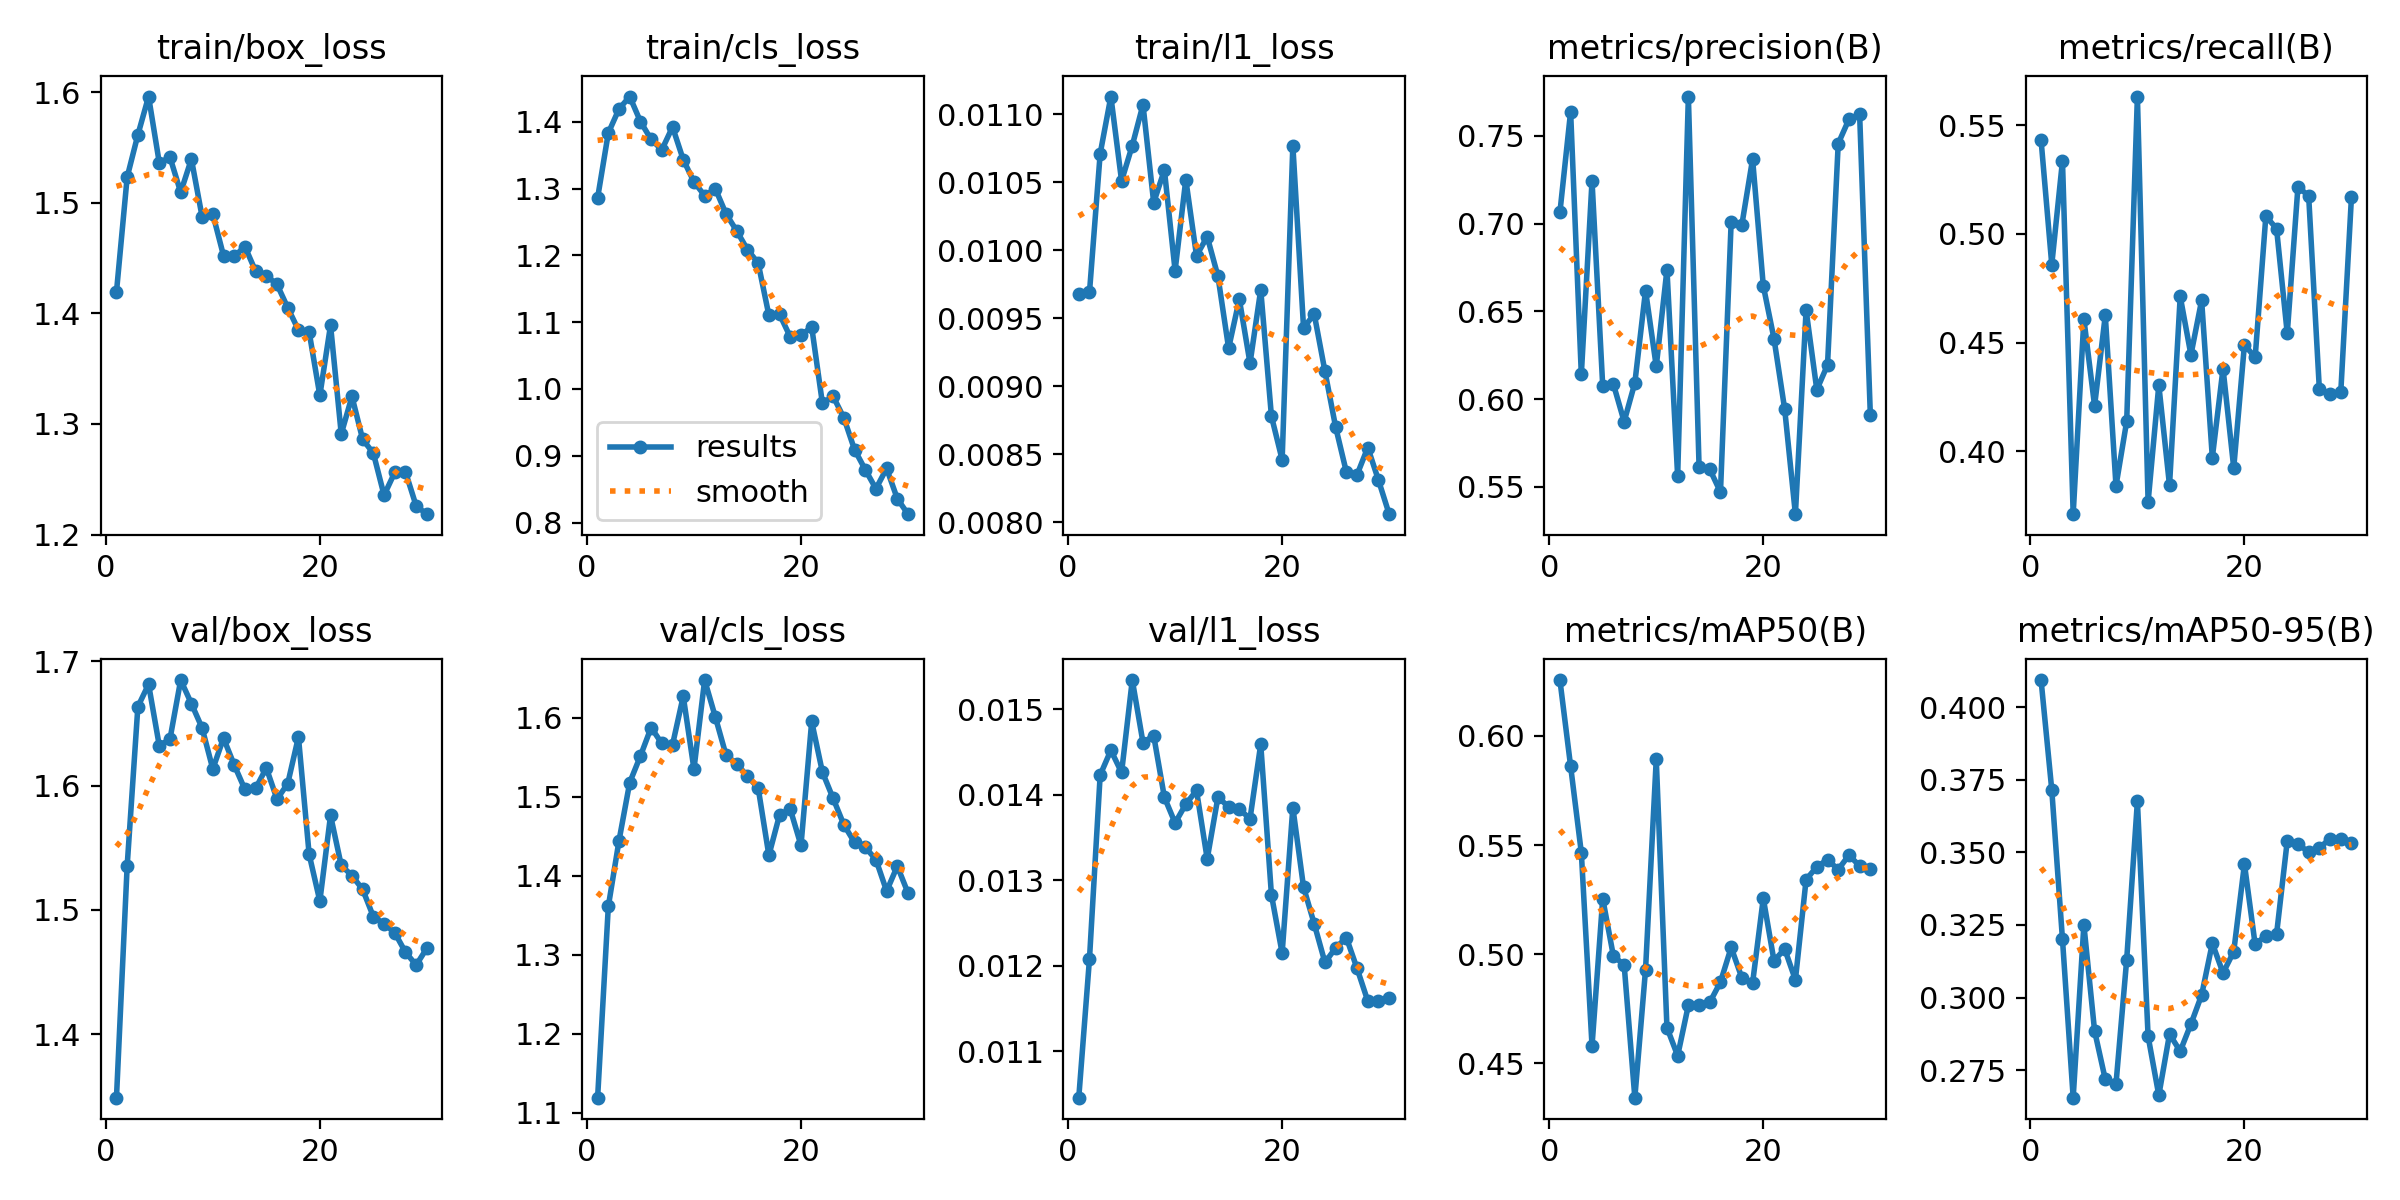

E2_scratch


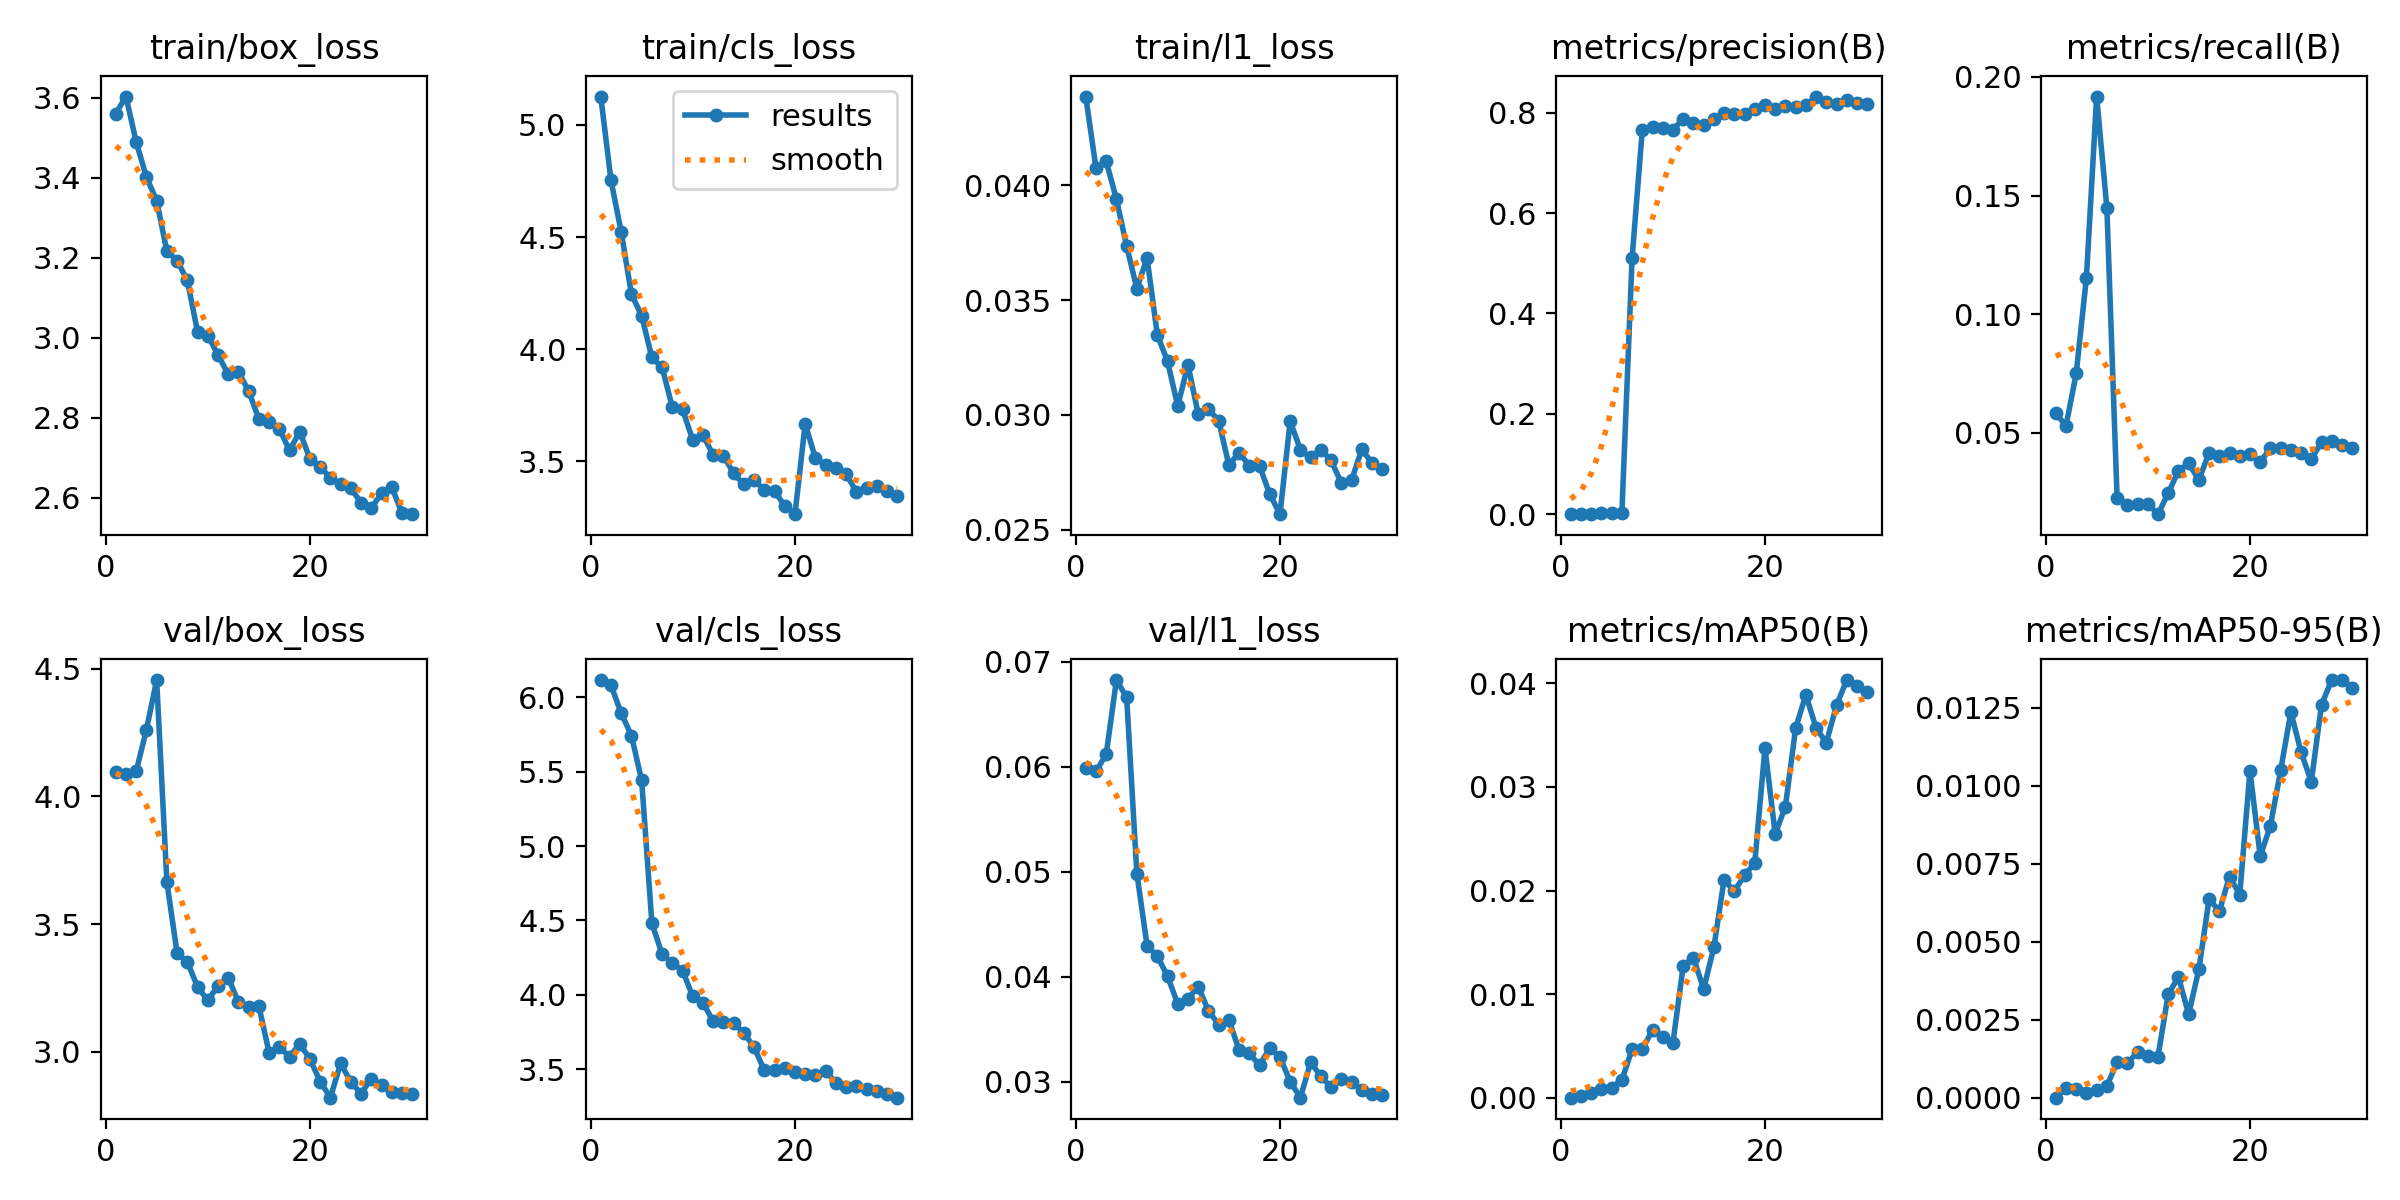

In [ ]:
from IPython.display import Image, display
for e in ["E1_pretrained", "E3_tuning", "E2_scratch"]:
    print(e)
    display(Image(f"hasil_praktik/{e}/results.png"))

In [ ]:
import pandas as pd
for e in ["E1_pretrained", "E2_scratch", "E3_tuning"]:
    d = pd.read_csv(f"hasil_praktik/{e}/results.csv")
    d.columns = [c.strip() for c in d.columns]
    col = [c for c in d.columns if "mAP50-95" in c][0]
    i = d[col].idxmax()
    print(e, "| epoch terbaik:", int(d.loc[i, "epoch"]), "| mAP50-95:", round(d.loc[i, col], 3),
          "| epoch terakhir:", round(d[col].iloc[-1], 3))

E1_pretrained | epoch terbaik: 1 | mAP50-95: 0.354 | epoch terakhir: 0.342
E2_scratch | epoch terbaik: 28 | mAP50-95: 0.013 | epoch terakhir: 0.013
E3_tuning | epoch terbaik: 1 | mAP50-95: 0.409 | epoch terakhir: 0.353


In [ ]:
from ultralytics import YOLO
D = "dataset_v1/data.yaml"
print("=== E1 pada 416 (val) ===");  YOLO("hasil_praktik/E1_pretrained/weights/best.pt").val(data=D, split="val", imgsz=416, plots=False, verbose=True)
print("=== E1 pada 640 (val) ===");  YOLO("hasil_praktik/E1_pretrained/weights/best.pt").val(data=D, split="val", imgsz=640, plots=False, verbose=True)
print("=== E3 pada 640 (val) ===");  YOLO("hasil_praktik/E3_tuning/weights/best.pt").val(data=D, split="val", imgsz=640, plots=False, verbose=True)

=== E1 pada 416 (val) ===
Ultralytics 8.4.178 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n summary (fused): 121 layers, 2,390,464 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2953.1±1035.7 MB/s, size: 148.2 KB)
val: Scanning /content/dataset_v1/labels/val.cache... 132 images, 11 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 132/132 19.8Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 9/9 6.4it/s 1.4s
                   all        132        519      0.591      0.525      0.572      0.366
                person        105        397      0.759      0.582      0.659      0.378
                laptop         11         20      0.549       0.55      0.548      0.394
                    tv          8         12      0.403      0.667      0.711      0.443
                 chair         32         90      0.651        0.3      0.372      0.249
Speed: 0.3ms prep

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0, 1, 2, 3])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7e94f4b62490>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
          0

In [22]:
!zip -rq hasil_{NIM}.zip dataset_v1 hasil_praktik hasil_praktik_{NIM}.txt hasil_praktik_{NIM}.csv dataset_yolo/cek_visual
from google.colab import files
files.download(f"hasil_{NIM}.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [24]:
from google.colab import drive
drive.mount('/content/drive')
!cp hasil_{NIM}.zip /content/drive/MyDrive/

Mounted at /content/drive


In [25]:
import os, shutil
os.makedirs("github_upload/hasil_praktik", exist_ok=True)
for e in ["E1_pretrained", "E2_scratch", "E3_tuning"]:
    os.makedirs(f"github_upload/hasil_praktik/{e}", exist_ok=True)
    for f in ["results.png", "results.csv", "args.yaml"]:
        shutil.copy(f"hasil_praktik/{e}/{f}", f"github_upload/hasil_praktik/{e}/{f}")
for ext in ["txt", "csv"]:
    shutil.copy(f"hasil_praktik_{NIM}.{ext}", "github_upload/")
shutil.make_archive("github_upload", "zip", "github_upload")
from google.colab import files
files.download("github_upload.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>